# 07 - Random Forest Classification

Part of the **Data Science Learning** project. Explanations, comments, and notebook messages are in English.

## Learning objectives
Combine many decision trees and evaluate a random forest.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_diabetes, make_blobs
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42

In [2]:
dataset = load_breast_cancer(as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(dataset.data, dataset.target, test_size=0.2, random_state=RANDOM_STATE, stratify=dataset.target)

## Compare forest sizes

In [3]:
from sklearn.ensemble import RandomForestClassifier

rows = []
for n_trees in [10, 50, 100, 200]:
    model = RandomForestClassifier(n_estimators=n_trees, random_state=RANDOM_STATE, n_jobs=-1)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({"n_estimators": n_trees, "accuracy": accuracy_score(y_test, pred), "f1": f1_score(y_test, pred)})

pd.DataFrame(rows)

,n_estimators,accuracy,f1
0,10,0.938596,0.951049
1,50,0.956140,0.965517
2,100,0.956140,0.965517
3,200,0.956140,0.965517


## Feature importance

              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



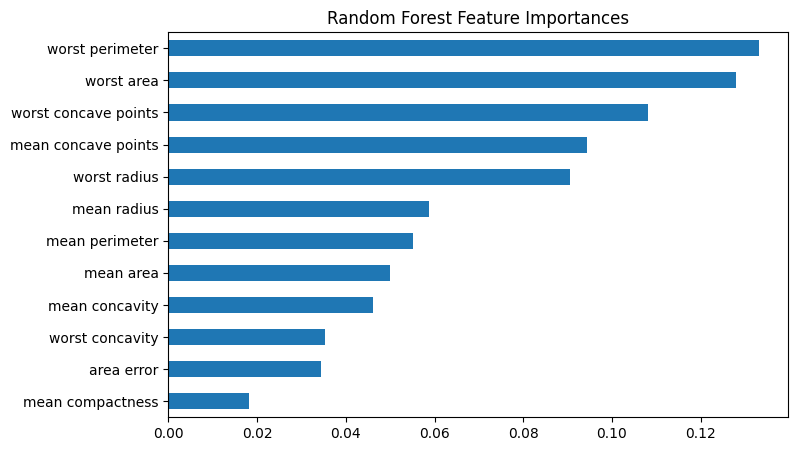

In [4]:
model = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
model.fit(X_train, y_train)
pred = model.predict(X_test)
print(classification_report(y_test, pred, target_names=dataset.target_names))
pd.Series(model.feature_importances_, index=dataset.feature_names).nlargest(12).sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Random Forest Feature Importances")
plt.show()

## Exercises
1. Change `max_features`.
2. Compare with a single decision tree.
3. Evaluate with cross-validation.